# code_122 · Seasonality, regression and filtered latent dynamics

**Book:** section 24.2. A self-contained forecasting laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_24_GUIDE.md), [run evidence](../CHAPTER_24_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_122).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2722;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
import statsmodels
VERSIONS['statsmodels']=statsmodels.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2722


<a id="classical-forecast-contract"></a>
 ## Classical families encode different temporal assumptions
 Generate sixty days of hourly demand with a drifting latent level, daily seasonality, preannounced occupancy, ambient variation and autocorrelated noise. First720 hours fit fixed configurations; origins720–936 describe development behavior and origins960–1416 assess frozen models, every24hours with a24-hour horizon. Native statsmodels0.15.0 implementations provide additive Holt–Winters, ARIMA(1,1,1) with drift, ARMA-error dynamic regression on known calendar/occupancy/trend, a raw VAR(2) diagnostic on demand/ambient, a differenced regression-residual VAR(2), and a local-level/deterministic-seasonal structural model with occupancy. Add lag-Ridge and daily seasonal naive. The raw VAR diagnostic violates its stationary-input assumption on a drifting seasonal series. The second VAR removes a source-fitted known-calendar/occupancy/trend regression and differences its demand residual; that repair also changes the admitted predictor representation. These families intentionally differ in covariates and assumptions; no exhaustive or equal-capacity tuning contest is claimed. Parameters fit only source data. Each origin filters or updates states from its observed prefix without refitting coefficients. Future realized ambient is not supplied. A separate retrospective smoother audit changes later observations with the fitted parameters held fixed.


Native optimizer convergence: {'Holt-Winters': True, 'ARIMA': True, 'Dynamic regression': True, 'Structural state': True}


,model,development_MSE,final_MSE,horizon_1_MSE,horizon_24_MSE
0,Seasonal naive,1.192394,1.687457,0.324906,0.406543
1,Holt-Winters,0.534262,0.781457,0.113500,0.398935
2,ARIMA,2.738975,2.725781,0.342196,0.469510
3,Dynamic regression,0.112837,0.246182,0.119588,0.339778
4,Lag Ridge,0.125637,0.267520,0.236262,0.340791
5,Raw VAR,3.424475,6.385160,0.616685,3.991898
6,Differenced VAR,0.106639,0.177624,0.109842,0.263281
7,Structural state,0.161178,0.262494,0.126776,0.374259


,model,source_residual_count,lag1_correlation,lag24_correlation
0,Seasonal naive,696,0.800837,-0.516165
1,Holt-Winters,672,-0.049617,-0.166969
2,ARIMA,672,-0.008904,0.643623
3,Dynamic regression,672,0.007353,0.013047
4,Lag Ridge,696,0.502682,0.017497
5,Raw VAR,718,-0.024014,0.679366
6,Differenced VAR,717,-0.015501,0.033639
7,Structural state,672,0.056196,0.019075


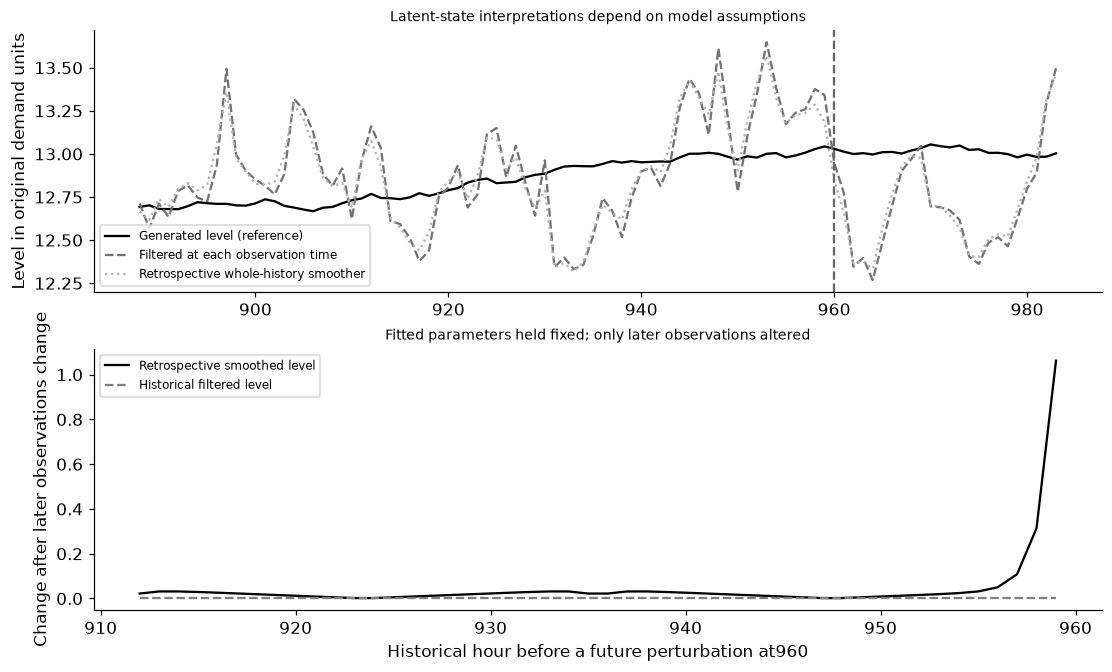

In [2]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.statespace.structural import UnobservedComponents
from statsmodels.tsa.api import VAR
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
T=1440;H=24;fit_end=720;time_index=np.arange(T);hour=time_index%24;known_day_active=rng.binomial(1,.8,T//24);occupancy=(np.repeat(known_day_active,24)*((hour>=9)&(hour<18))).astype(float);level=10+np.cumsum(.003+rng.normal(0,.015,T));ambient=np.zeros(T);noise=np.zeros(T)
for t in range(1,T):ambient[t]=.75*ambient[t-1]+rng.normal(0,.5);noise[t]=.55*noise[t-1]+rng.normal(0,.2)
demand=level+2.5*occupancy+2*np.sin(2*np.pi*hour/24)+.5*np.cos(2*np.pi*hour/24)+.35*ambient+noise;center=demand[:fit_end].mean();scale=demand[:fit_end].std();ys=(demand-center)/scale;exo_raw=np.c_[occupancy,np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),time_index/fit_end];exo_scaler=StandardScaler().fit(exo_raw[:fit_end]);exo=exo_scaler.transform(exo_raw)
ets=ExponentialSmoothing(ys[:fit_end],trend='add',seasonal='add',seasonal_periods=24,initialization_method='estimated').fit(optimized=True,use_brute=False,method='L-BFGS-B',minimize_kwargs={'options':{'maxiter':500}})
arima_model=ARIMA(ys[:fit_end],order=(1,1,1),trend='t');arima_start=np.array([0.,.2,-.2,1.]);assert arima_model.param_names==['x1','ar.L1','ma.L1','sigma2'];arima=arima_model.fit(start_params=arima_start,method_kwargs={'maxiter':500})
dynamic_model=SARIMAX(ys[:fit_end],exog=exo[:fit_end],order=(1,0,1),trend='c');dynamic_start=np.zeros(dynamic_model.k_params);dynamic_start[-1]=1;dynamic=dynamic_model.fit(start_params=dynamic_start,disp=False,maxiter=500)
def structural(values,occupancy_values):return UnobservedComponents(values,level='local level',seasonal=24,stochastic_seasonal=False,exog=occupancy_values[:,None])
state_model=structural(ys[:fit_end],occupancy[:fit_end]);state_start=np.array([.05,.001,1.]);assert state_model.param_names==['sigma2.irregular','sigma2.level','beta.x1'];state=state_model.fit(start_params=state_start,disp=False,maxiter=500)
ambient_center=ambient[:fit_end].mean();ambient_scale=ambient[:fit_end].std();joint=np.c_[ys,(ambient-ambient_center)/ambient_scale];var=VAR(joint[:fit_end]).fit(maxlags=2,trend='c');calendar_design=np.c_[np.ones(T),exo_raw];calendar_coefficients=np.linalg.lstsq(calendar_design[:fit_end],ys[:fit_end],rcond=None)[0];calendar_mean=calendar_design@calendar_coefficients;residual_series=ys-calendar_mean;var_stationary_joint=np.c_[np.diff(residual_series),joint[1:,1]];var_stationary=VAR(var_stationary_joint[:fit_end-1]).fit(maxlags=2,trend='c')
def lag_features(history,t):return np.r_[history[t-1],history[t-24],exo[t]]
lag_x=np.array([lag_features(ys,t) for t in range(24,fit_end)]);lag_y=ys[24:fit_end];lag_scaler=StandardScaler().fit(lag_x);lag=Ridge(alpha=1).fit(lag_scaler.transform(lag_x),lag_y)
convergence={'Holt-Winters':bool(ets.mle_retvals.success),'ARIMA':bool(arima.mle_retvals['converged']),'Dynamic regression':bool(dynamic.mle_retvals['converged']),'Structural state':bool(state.mle_retvals['converged'])};print('Native optimizer convergence:',convergence);assert all(convergence.values())
def forecast(name,origin,values=ys):
    if name=='Seasonal naive':return values[origin-24:origin].copy()
    if name=='Holt-Winters':
        params=ets.params;updated=ExponentialSmoothing(values[:origin],trend='add',seasonal='add',seasonal_periods=24,initialization_method='known',initial_level=params['initial_level'],initial_trend=params['initial_trend'],initial_seasonal=params['initial_seasons']).fit(smoothing_level=params['smoothing_level'],smoothing_trend=params['smoothing_trend'],smoothing_seasonal=params['smoothing_seasonal'],optimized=False);return np.asarray(updated.forecast(H))
    if name=='ARIMA':return np.asarray(arima.apply(values[:origin],refit=False).forecast(H))
    if name=='Dynamic regression':return np.asarray(dynamic.apply(values[:origin],exog=exo[:origin],refit=False).forecast(H,exog=exo[origin:origin+H]))
    if name=='Structural state':return np.asarray(structural(values[:origin],occupancy[:origin]).filter(state.params).forecast(H,exog=occupancy[origin:origin+H,None]))
    if name=='Differenced VAR':
        residual=values[:origin]-calendar_mean[:origin];past=np.c_[np.diff(residual),joint[1:origin,1]];future=var_stationary.forecast(past[-var_stationary.k_ar:],H);return residual[-1]+np.cumsum(future[:,0])+calendar_mean[origin:origin+H]
    if name=='Raw VAR':return var.forecast(np.c_[values[:origin],joint[:origin,1]][-var.k_ar:],H)[:,0]
    history=list(values[:origin])
    for horizon in range(H):history.append(float(lag.predict(lag_scaler.transform(lag_features(np.array(history),origin+horizon)[None]))[0]))
    return np.array(history[origin:origin+H])
names=['Seasonal naive','Holt-Winters','ARIMA','Dynamic regression','Lag Ridge','Raw VAR','Differenced VAR','Structural state'];development_origins=np.arange(720,960-H+1,24);final_origins=np.arange(960,T-H+1,24);rows=[];forecast_store={}
for name in names:
    development=np.array([forecast(name,o) for o in development_origins]);prediction=np.array([forecast(name,o) for o in final_origins]);truth=np.array([ys[o:o+H] for o in final_origins]);dev_truth=np.array([ys[o:o+H] for o in development_origins]);error=(prediction-truth)**2*scale**2;forecast_store[name]=prediction*scale+center;rows.append({'model':name,'development_MSE':float(np.mean((development-dev_truth)**2)*scale**2),'final_MSE':float(error.mean()),'horizon_1_MSE':float(error[:,0].mean()),'horizon_24_MSE':float(error[:,-1].mean()),'MSE_by_horizon':error.mean(0).tolist()})
# Filtering is causal with frozen parameters; retrospective smoothing deliberately is not.
origin=960;full=structural(ys,occupancy).smooth(state.params);changed=ys.copy();changed[origin:]+=3;changed_full=structural(changed,occupancy).smooth(state.params);torch.testing.assert_close(torch.tensor(full.filtered_state[:,:origin]),torch.tensor(changed_full.filtered_state[:,:origin]),atol=1e-10,rtol=1e-10);prefix=structural(ys[:origin],occupancy[:origin]).filter(state.params);np.testing.assert_allclose(prefix.filtered_state[:,-1],full.filtered_state[:,origin-1],atol=1e-10)
smoothing_change=np.abs(changed_full.smoothed_state[0,:origin]-full.smoothed_state[0,:origin])*scale;assert smoothing_change.max()>1e-5
for name in names:np.testing.assert_array_equal(forecast(name,origin,changed),forecast(name,origin))
difference=np.diff(ys[:fit_end]);np.testing.assert_allclose(np.r_[ys[0],ys[0]+np.cumsum(difference)],ys[:fit_end],atol=1e-12);seasonal_difference=ys[24:fit_end]-ys[:fit_end-24];reconstructed=list(ys[:24])
for value in seasonal_difference:reconstructed.append(value+reconstructed[-24])
np.testing.assert_allclose(reconstructed,ys[:fit_end],atol=1e-12)
training_residuals={'Seasonal naive':ys[24:fit_end]-ys[:fit_end-24],'Holt-Winters':np.asarray(ets.resid)[48:],'ARIMA':np.asarray(arima.resid)[48:],'Dynamic regression':np.asarray(dynamic.resid)[48:],'Lag Ridge':lag_y-lag.predict(lag_scaler.transform(lag_x)),'Raw VAR':var.resid[:,0],'Differenced VAR':var_stationary.resid[:,0],'Structural state':np.asarray(state.resid)[48:]};residual_rows=[]
for name,residual in training_residuals.items():residual_rows.append({'model':name,'source_residual_count':len(residual),'lag1_correlation':float(np.corrcoef(residual[1:],residual[:-1])[0,1]),'lag24_correlation':float(np.corrcoef(residual[24:],residual[:-24])[0,1])})
RESULTS.update(comparisons=rows,source_residual_diagnostics=residual_rows,optimizer_converged=convergence,source_hours=fit_end,total_hours=T,development_origins=development_origins.tolist(),final_origins=final_origins.tolist(),horizon=H,VAR_order=var.k_ar,VAR_stable=bool(var.is_stable()),differenced_VAR_order=var_stationary.k_ar,differenced_VAR_stable=bool(var_stationary.is_stable()),ARIMA_parameters=dict(zip(arima.param_names,map(float,arima.params))),dynamic_parameters=dict(zip(dynamic.param_names,map(float,dynamic.params))),structural_parameters=dict(zip(state.param_names,map(float,state.params))),future_perturbation_changes_historical_filtered_state=False,future_perturbation_historical_smoothed_level_max_difference=float(smoothing_change.max()),prefix_filtered_state_max_error=float(np.max(np.abs(prefix.filtered_state[:,-1]-full.filtered_state[:,origin-1]))));display(pd.DataFrame([{k:v for k,v in r.items() if k!='MSE_by_horizon'} for r in rows]));display(pd.DataFrame(residual_rows))
fig,axes=plt.subplots(2,1,figsize=(10,6));window=slice(origin-72,origin+24);times=time_index[window];axes[0].plot(times,level[window],color='black',label='Generated level (reference)');axes[0].plot(times,full.filtered_state[0,window]*scale+center,'--',color='.45',label='Filtered at each observation time');axes[0].plot(times,full.smoothed_state[0,window]*scale+center,':',color='.7',label='Retrospective whole-history smoother');axes[0].axvline(origin,color='.4',linestyle='--');axes[0].set(ylabel='Level in original demand units',title='Latent-state interpretations depend on model assumptions');axes[0].legend(fontsize=8)
axes[1].plot(np.arange(origin-48,origin),smoothing_change[-48:],color='black',label='Retrospective smoothed level');axes[1].plot(np.arange(origin-48,origin),np.zeros(48),'--',color='.5',label='Historical filtered level');axes[1].set(xlabel='Historical hour before a future perturbation at960',ylabel='Change after later observations change',title='Fitted parameters held fixed; only later observations altered');axes[1].legend(fontsize=8);plt.show()


<a id="classical-model-limits"></a>
 ## State updates are not parameter refits, and smoothing is not online filtering
 Additive Holt–Winters carries level/trend/daily seasonal state; ARIMA differences and models innovations; dynamic regression uses known exogenous calendar/occupancy/trend with ARMA errors. The raw VAR jointly predicts drifting demand and ambient without a valid stationary-input treatment; its failure remains visible. The additional VAR fits demand differences after a source-only known-calendar/occupancy/trend regression, alongside ambient, and reconstructs demand by summing predicted residual differences. It also uses known future regression covariates, so it changes both stationarity treatment and predictor information, not just one isolated switch. Neither VAR observes realized future ambient. The structural model separates a stochastic level from deterministic seasonal states and occupancy, while its misspecified residual assumptions need inspection. All origin-specific state calculations keep fitted coefficients and initial fitted states/variances fixed. The state model's retrospective smoother accesses later observations and is explicitly excluded from origin forecasts. Training residual autocorrelation is a diagnostic of these fits, not a significance test based on independent forecast errors. Development losses are reported for fixed configurations, with no post-final tuning or universal family winner claim.


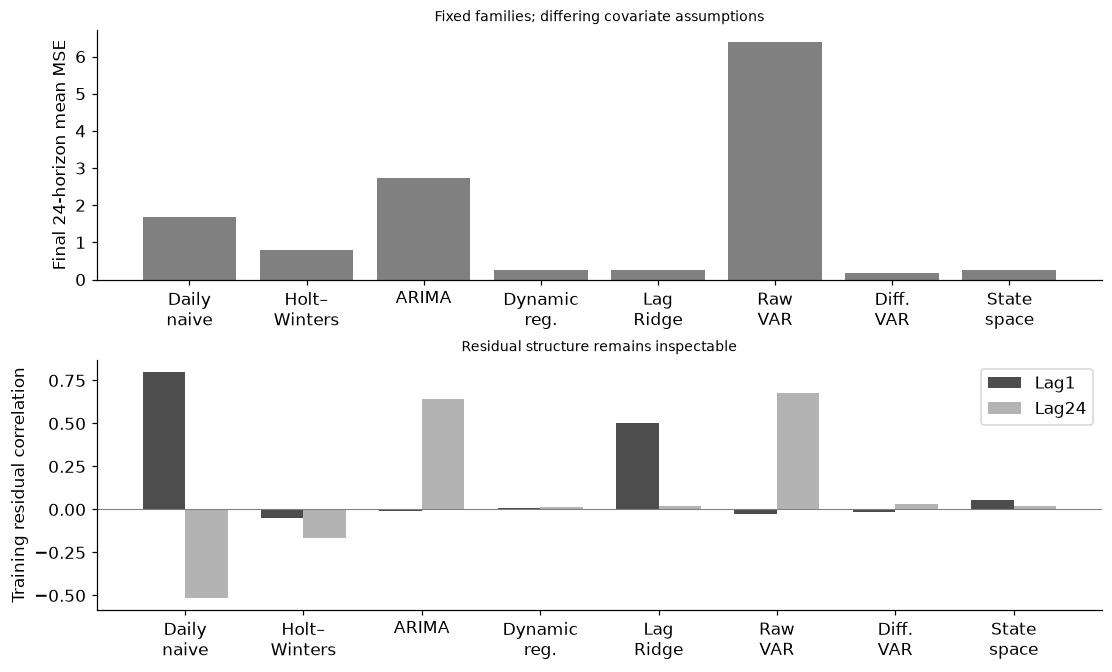

In [3]:
labels=['Daily\nnaive','Holt–\nWinters','ARIMA','Dynamic\nreg.','Lag\nRidge','Raw\nVAR','Diff.\nVAR','State\nspace'];fig,axes=plt.subplots(2,1,figsize=(10,6));xx=np.arange(len(names));axes[0].bar(xx,[r['final_MSE'] for r in rows],color='.5');axes[0].set(xticks=xx,xticklabels=labels,ylabel='Final 24-horizon mean MSE',title='Fixed families; differing covariate assumptions')
axes[1].bar(xx-.18,[r['lag1_correlation'] for r in residual_rows],width=.36,color='.3',label='Lag1');axes[1].bar(xx+.18,[r['lag24_correlation'] for r in residual_rows],width=.36,color='.7',label='Lag24');axes[1].axhline(0,color='.5',linewidth=.7);axes[1].set(xticks=xx,xticklabels=labels,ylabel='Training residual correlation',title='Residual structure remains inspectable');axes[1].legend();plt.show()
assert all(np.isfinite(r['final_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_122','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['native seasonal exponential smoothing', 'native ARIMA and dynamic regression', 'lag regression and vector autoregression', 'native structural state-space filtering', 'future-sensitive smoothing audit'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["native seasonal exponential smoothing", "native ARIMA and dynamic regression", "lag regression and vector autoregression", "native structural state-space filtering", "future-sensitive smoothing audit"], "elapsed_seconds": 2.705, "example_id": "code_122", "hardware": "Darwin arm64 CPU", "results": {"ARIMA_parameters": {"ar.L1": 0.5877199935015383, "ma.L1": -0.49061038600582974, "sigma2": 0.21894757095953954, "x1": 0.0016257132265919347}, "VAR_order": 2, "VAR_stable": true, "comparisons": [{"MSE_by_horizon": [0.32490614148862945, 0.22535905224548453, 0.3035791774414116, 0.28125749662037947, 0.23948883103964153, 0.1387800070048713, 0.19466186080758768, 0.2935847218716103, 0.3789352066741135, 4.760605951048442, 3.7709456400809023, 4.7523084342553945, 4.405111818406214, 4.140221525883802, 3.7324832773103687, 3.835789062902923, 3.1767047422448402, 3.7767997936081033, 0.261249419968247, 0.22076348994758263, 0.2819571901983435, 0.1959475360345